In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from google.colab import files

uploaded = files.upload()


Saving archive (3).zip to archive (3).zip


In [4]:

# Get the uploaded file name
filename = next(iter(uploaded))

# Load the dataset
df = pd.read_csv(filename, encoding="latin-1")

# Display dataset details
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 2)

Column names:
['v1', 'v2']

First 5 rows:


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:

df = df[['v1', 'v2']].copy()
df.columns = ['label', 'message']

df = df.dropna(subset=['label', 'message'])
df['message'] = df['message'].astype(str).str.strip()
df = df[df['message'] != '']
df = df.drop_duplicates(subset=['message'])

df = df.sample(n=2000, random_state=42)
df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Total messages:", len(df))
print(df['label'].value_counts())
display(df.head())


KeyError: "None of [Index(['v1', 'v2'], dtype='object')] are in the [columns]"

In [9]:
print(df.columns.tolist())
display(df.head())

['label', 'message']


,label,message
0,ham,&lt;#&gt; am I think? Should say on syllabus
1,ham,2mro i am not coming to gym machan. Goodnight.
2,ham,Carlos'll be here in a minute if you still nee...
3,ham,Id onluy matters when getting on from offcampus
4,ham,Except theres a chick with huge boobs.


In [11]:

# Remove missing values
df = df.dropna(subset=['label', 'message'])

# Remove empty messages
df['message'] = df['message'].astype(str).str.strip()
df = df[df['message'] != '']

# Remove duplicate messages
df = df.drop_duplicates(subset=['message'])

# Select 2,000 messages
df = df.sample(n=min(2000, len(df)), random_state=42)
df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Total messages:", len(df))

print("\nHam and Spam counts:")
print(df['label'].value_counts())

display(df.head())


Dataset cleaned successfully!
Total messages: 2000

Ham and Spam counts:
label
ham     1740
spam     260
Name: count, dtype: int64


,label,message
0,ham,Thank u!
1,ham,Have your lunch and come quickly and open the ...
2,ham,I plane to give on this month end.
3,ham,Do I? I thought I put it back in the box
4,ham,"Em, its olowoyey@ usc.edu have a great time in..."


In [13]:

# Import regular expressions
import re

# Clean the SMS text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply text cleaning
df['message'] = df['message'].apply(clean_text)

# Convert labels into numbers
# ham = 0, spam = 1
df['label'] = df['label'].str.strip().str.lower()
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print("Text preprocessing completed!")
display(df.head())


AttributeError: Can only use .str accessor with string values!

In [15]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Convert words into numbers
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(df['message'])

sequences = tokenizer.texts_to_sequences(df['message'])

# Make all messages the same length
max_length = 100
X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

# Store the labels
y = df['label'].values

print("Tokenization completed!")
print("Number of messages:", len(X))
print("Shape of input data:", X.shape)
print("Shape of labels:", y.shape)

print("\nExample of a numerical sequence:")
print(X[0])


Tokenization completed!
Number of messages: 2000
Shape of input data: (2000, 100)
Shape of labels: (2000,)

Example of a numerical sequence:
[299   7   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0]


In [17]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 1600
Testing messages: 400


In [21]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=5000, output_dim=32, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:

model.build(input_shape=(None, max_length))
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 32)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)


Epoch 1/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 1.0000 - loss: 0.0116 - val_accuracy: 0.9625 - val_loss: 0.1381
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 1.0000 - loss: 0.0075 - val_accuracy: 0.9563 - val_loss: 0.1729
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 1.0000 - loss: 0.0059 - val_accuracy: 0.9500 - val_loss: 0.1957
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 1.0000 - loss: 0.0045 - val_accuracy: 0.9500 - val_loss: 0.2148
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 0.9500 - val_loss: 0.2252


Accuracy: 0.9775
Precision: 0.9216
Recall: 0.9038
F1-score: 0.9126


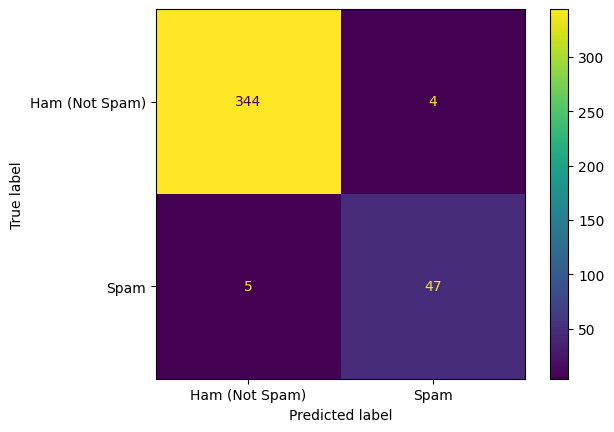

In [27]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Predict on test data
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

# Calculate performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham (Not Spam)", "Spam"]
)

display_matrix.plot()
plt.show()


In [28]:

def predict_sms(message):
    cleaned = clean_text(message)
    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    print("Message:", message)
    print("Prediction:", "SPAM" if probability >= 0.5 else "NOT SPAM")
    print("Spam probability:", round(probability * 100, 2), "%")
    print("-" * 40)


predict_sms("Congratulations! You won a free prize. Click now!")
predict_sms("Hi, are you coming to college tomorrow?")
predict_sms("Please call me when you reach home.")


Message: Congratulations! You won a free prize. Click now!
Prediction: SPAM
Spam probability: 95.13 %
----------------------------------------
Message: Hi, are you coming to college tomorrow?
Prediction: NOT SPAM
Spam probability: 0.06 %
----------------------------------------
Message: Please call me when you reach home.
Prediction: NOT SPAM
Spam probability: 0.14 %
----------------------------------------
